<a href="https://colab.research.google.com/github/abhimanyu-05-2006/YuvaIntern-ML-Engineer-Tasks/blob/main/Task_3_EDA_%26_Real_World_Dataset_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_california_housing

# Ingest California Housing Benchmark Dataset
housing_data = fetch_california_housing(as_frame=True)
df_raw = housing_data.frame

# Rename columns for domain-level clarity
df = df_raw.rename(columns={
    'MedInc': 'median_income',
    'HouseAge': 'housing_median_age',
    'AveRooms': 'avg_rooms',
    'AveBedrms': 'avg_bedrooms',
    'Population': 'population',
    'AveOccup': 'avg_occupancy',
    'MedHouseVal': 'target_median_house_val'
})

print(f"[DATASET INGESTION] Dataset Dimensions: {df.shape[0]} rows, {df.shape[1]} columns")
print("\n--- Summary Statistics (Raw Data) ---")
print(df.describe().T[['mean', 'std', 'min', '50%', 'max']])

[DATASET INGESTION] Dataset Dimensions: 20640 rows, 9 columns

--- Summary Statistics (Raw Data) ---
                                mean          std         min          50%  \
median_income               3.870671     1.899822    0.499900     3.534800   
housing_median_age         28.639486    12.585558    1.000000    29.000000   
avg_rooms                   5.429000     2.474173    0.846154     5.229129   
avg_bedrooms                1.096675     0.473911    0.333333     1.048780   
population               1425.476744  1132.462122    3.000000  1166.000000   
avg_occupancy               3.070655    10.386050    0.692308     2.818116   
Latitude                   35.631861     2.135952   32.540000    34.260000   
Longitude                -119.569704     2.003532 -124.350000  -118.490000   
target_median_house_val     2.068558     1.153956    0.149990     1.797000   

                                  max  
median_income               15.000100  
housing_median_age          52.000000 

In [2]:
# Feature Engineering: Structural Ratios
df_proc = df.copy()
df_proc['rooms_per_household'] = df_proc['avg_rooms'] / df_proc['avg_occupancy']
df_proc['bedrooms_ratio'] = df_proc['avg_bedrooms'] / df_proc['avg_rooms']

# Multi-Attribute IQR Capping for Realistic Distribution Cleaning
def cap_outliers_iqr(dataframe, features):
    df_clean = dataframe.copy()
    for col in features:
        Q1 = df_clean[col].quantile(0.25)
        Q3 = df_clean[col].quantile(0.75)
        IQR = Q3 - Q1
        upper_limit = Q3 + 1.5 * IQR
        lower_limit = Q1 - 1.5 * IQR
        df_clean[col] = np.clip(df_clean[col], lower_limit, upper_limit)
    return df_clean

engineered_cols = ['avg_rooms', 'avg_bedrooms', 'avg_occupancy', 'population']
df_clean = cap_outliers_iqr(df_proc, engineered_cols)

print("--- Feature Engineering & Capping Audit ---")
print(f"Original Records Retained: {len(df_clean)}")
print("Engineered Feature Metrics (Sample):")
print(df_clean[['rooms_per_household', 'bedrooms_ratio']].describe().T[['mean', 'std', '50%']])

--- Feature Engineering & Capping Audit ---
Original Records Retained: 20640
Engineered Feature Metrics (Sample):
                         mean       std       50%
rooms_per_household  1.976970  1.146020  1.937936
bedrooms_ratio       0.213075  0.058023  0.203181


--- Correlation with Target House Value ---
target_median_house_val    1.000000
median_income              0.688075
avg_rooms                  0.311003
rooms_per_household        0.209482
housing_median_age         0.105623
population                -0.032739
Longitude                 -0.045967
avg_bedrooms              -0.096055
Latitude                  -0.144160
bedrooms_ratio            -0.255624
avg_occupancy             -0.281148
Name: target_median_house_val, dtype: float64


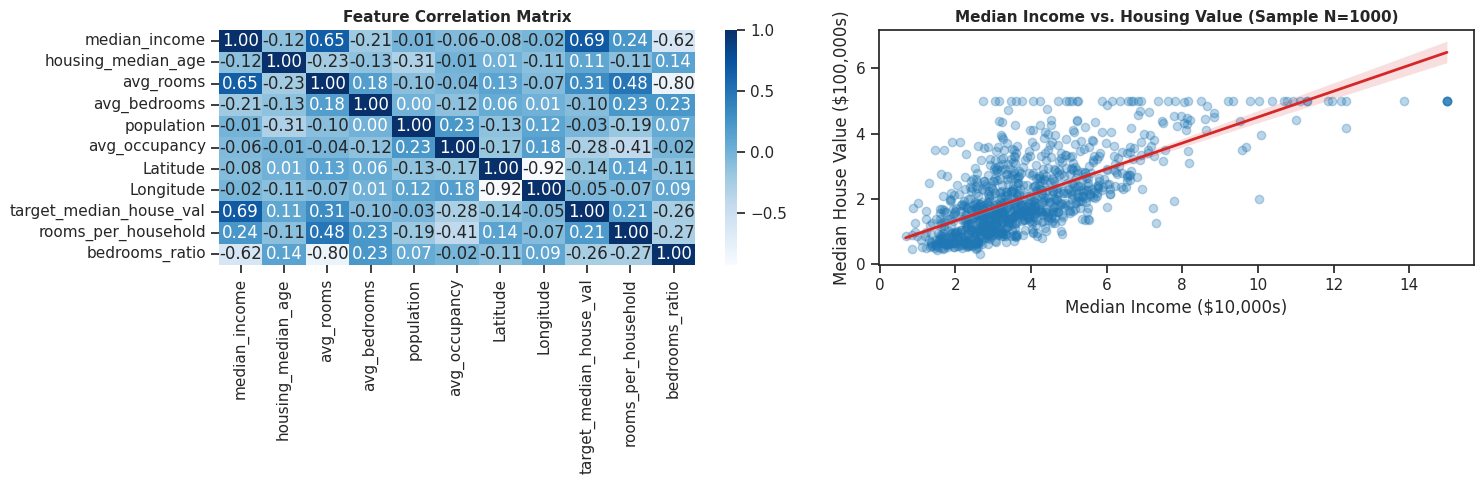

In [3]:
# Correlation Matrix Computation
corr_matrix = df_clean.corr()
top_corr_features = corr_matrix['target_median_house_val'].sort_values(ascending=False)

print("--- Correlation with Target House Value ---")
print(top_corr_features)

# Visual Suite: Distribution & Heatmap Plotting
sns.set_theme(style="ticks", palette="tab10")
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Plot 1: Correlation Heatmap
sns.heatmap(corr_matrix, ax=axes[0], annot=True, fmt=".2f", cmap="Blues", cbar=True)
axes[0].set_title("Feature Correlation Matrix", fontsize=11, fontweight='bold')

# Plot 2: Median Income vs Target Value Scatter
sns.regplot(
    ax=axes[1], data=df_clean.sample(1000, random_state=42),
    x='median_income', y='target_median_house_val',
    scatter_kws={'alpha': 0.3, 'color': '#1f77b4'}, line_kws={'color': '#d62728', 'linewidth': 2}
)
axes[1].set_title("Median Income vs. Housing Value (Sample N=1000)", fontsize=11, fontweight='bold')
axes[1].set_xlabel("Median Income ($10,000s)")
axes[1].set_ylabel("Median House Value ($100,000s)")

plt.tight_layout()
plt.show()